In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

In [5]:
# 1. Load Dataset
df = pd.read_csv(r"C:/Users/Hp/Desktop/LP3/ML/uber.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

First Five Records:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647          

In [6]:
# 2. Data Preprocessing

# Remove unnecessary columns
df.drop(columns=["Unnamed: 0", "key"],
        errors="ignore", inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert pickup_datetime to datetime
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], utc=True, errors="coerce"
)

df.dropna(subset=["pickup_datetime"], inplace=True)

# Remove invalid records
df = df[
    (df["fare_amount"] > 0) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"] != 0) &
    (df["pickup_latitude"] != 0) &
    (df["dropoff_longitude"] != 0) &
    (df["dropoff_latitude"] != 0) &
    (df["passenger_count"].between(1, 6))
].copy()

print("\nDataset after preprocessing:")
print(df.head())

print("\nShape:", df.shape)


Dataset after preprocessing:
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  

Shape: (195313, 7)


In [7]:
# 3. Calculate Distance using Haversine Formula

def calculate_distance(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2) ** 2)

    c = 2 * np.arcsin(np.sqrt(a))

    return 6371 * c

df["distance"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero-distance and unrealistic trips
df = df[
    (df["distance"] > 0) &
    (df["distance"] <= 100)
].copy()

# Extract time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.dayofweek

df.drop(columns=["pickup_datetime"], inplace=True)

In [8]:
# 4. Identify Outliers using IQR

print("\nOutlier Detection:")

for col in ["fare_amount", "distance", "passenger_count"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

# Remove extreme fare outliers
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

df = df[
    (df["fare_amount"] >= max(0, Q1 - 1.5 * IQR)) &
    (df["fare_amount"] <= Q3 + 1.5 * IQR)
].copy()



Outlier Detection:
fare_amount Outliers: 16540
distance Outliers: 16045
passenger_count Outliers: 21863



Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.001204        -0.002014   
pickup_longitude      0.001204          1.000000        -0.993709   
pickup_latitude      -0.002014         -0.993709         1.000000   
dropoff_longitude     0.002047          0.999963        -0.993727   
dropoff_latitude     -0.002214         -0.993716         0.999953   
passenger_count       0.013017          0.009836        -0.010161   
distance              0.723498         -0.008440         0.008686   
hour                 -0.013121          0.002746        -0.002101   
day                   0.006575          0.018511        -0.019015   
month                 0.026705         -0.007082         0.007518   
weekday               0.020356          0.006676        -0.007260   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                 0.002047         -0.002214         0.013017   


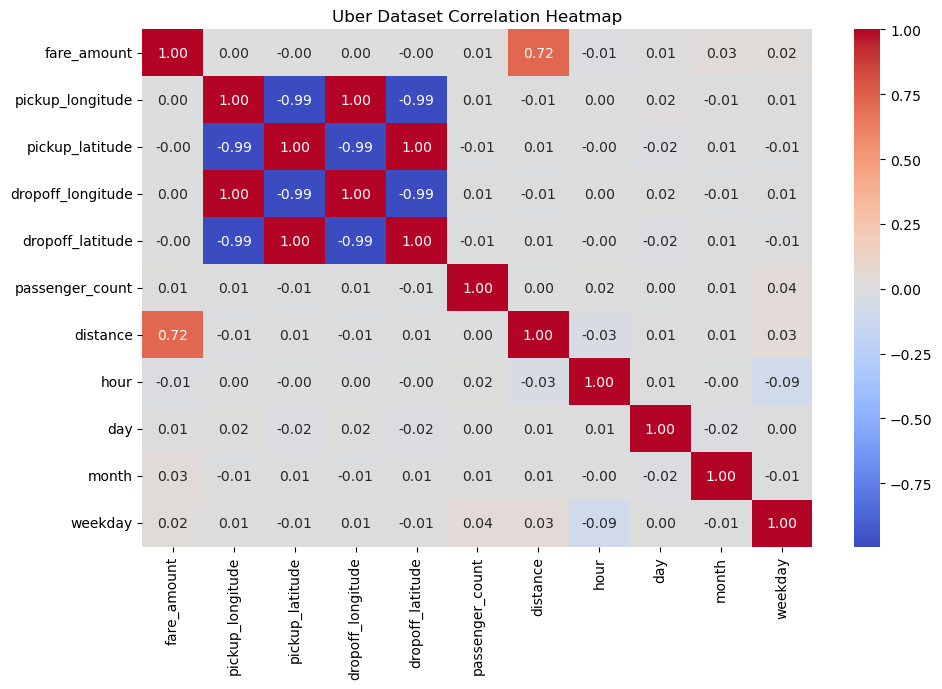

In [9]:
# 5. Correlation Analysis

correlation = df.corr()

print("\nCorrelation Matrix:")
print(correlation)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Uber Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()


In [10]:
# 6. Prepare Features and Target

X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
# 7. Linear Regression Model

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [12]:
# 8. Random Forest Regression Model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [13]:
# 9. Model Evaluation

def evaluate_model(name, actual, predicted):

    r2 = r2_score(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return [name, r2, rmse, mae]


lr_results = evaluate_model(
    "Linear Regression", y_test, lr_pred
)

rf_results = evaluate_model(
    "Random Forest Regression", y_test, rf_pred
)



 Linear Regression
R2 Score: 0.5891
RMSE: 2.6464
MAE: 1.8845

 Random Forest Regression
R2 Score: 0.7418
RMSE: 2.0979
MAE: 1.4822


In [14]:
# 10. Compare Both Models

results = pd.DataFrame(
    [lr_results, rf_results],
    columns=["Model", "R2 Score", "RMSE", "MAE"]
)

print("\nModel Comparison:")
print(results)



Model Comparison:
                      Model  R2 Score      RMSE       MAE
0         Linear Regression  0.589093  2.646401  1.884474
1  Random Forest Regression  0.741764  2.097937  1.482162


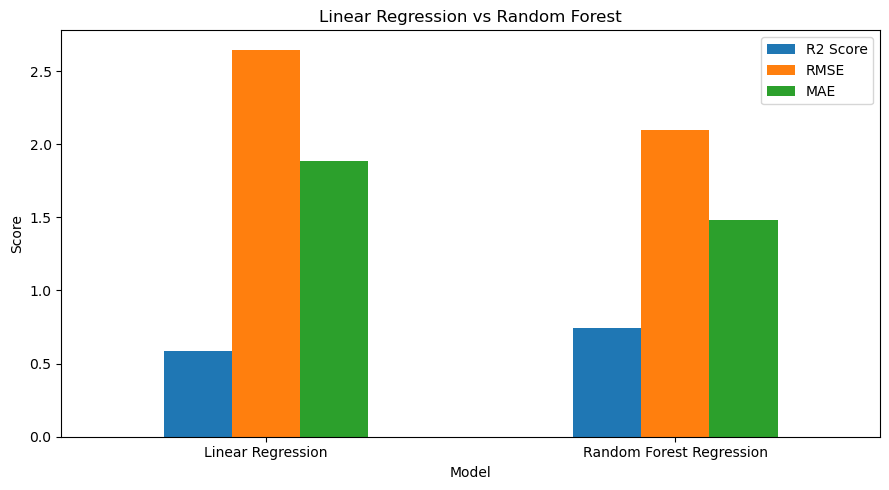

In [15]:
# 11. Visualize Model Comparison

results.set_index("Model")[
    ["R2 Score", "RMSE", "MAE"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Linear Regression vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [16]:
# 12. Predict Uber Fare

sample = X_test.iloc[[0]]

predicted_fare = rf_model.predict(sample)

print("\nSample Uber Fare Prediction:")
print("Predicted Fare:", round(predicted_fare[0], 2))
print("Actual Fare:", round(y_test.iloc[0], 2))


Sample Uber Fare Prediction:
Predicted Fare: 5.99
Actual Fare: 5.3
